# Miniproject 2: The project

## Introduction
The error function is defined as
$$
\mbox{erf}(z) = \frac{2}{\sqrt{\pi}}\int_0^z e^{-t^2} dt.
$$

In python its value for a given $z$, e.g. for  $z=$ 1 is found by calling 
```python
math.erf(1)
```
The Taylor polynomial, $P_N(z)$, of order $N$ about the origin which approximates $\mbox{erf}(z)$ is
$$
P_N(z) = \frac{2}{\sqrt{\pi}}\sum_{n=0}^N \frac{(-1)^nz^{2n+1}}{n!(2n+1)}.
$$

We want to study how well $P_N(z)$ approximates $\mbox{erf}(z)$. 

Before completing this miniproject be sure to study Guided Example 2.

## Tasks
To this objective:
* Write a python function `errfun` that takes as input arguments:
  * the order `N` of the approximating Taylor polynomial 
  * the value `z` at which the erf is evaluated.
The function returns the Taylor polynomial at z for the chosen N. 
Use `math.factorial(n)` to calculate the factorial of `n`.
_Tip: Before proceeding to the next task, make sure that you coded the Taylor plynomial correctly by verifying that it returns the same value as `math.erf`. For example, for `z = 1` and `N = 18` the polynomial should return the same as the python function._
* Write a python function `ErrSequence` 
 that takes as input arguments:
  * the value `z` at which the erf is evaluated
  * the minimum difference `eps`. 
The function returns the list of the absolute value of the differences (use `abs`) between the erf function calculated with `math.erf` (that we consider as the reference value) and Taylor polynomial of increasing order calculated with `errfun`. Use a `while` loop that appends values to the list while the difference is larger than `eps`.
* Write the main script that 
  * generates the lists of differences for `z= 0.1, 1.0, 2.0, 3.0`. Choose `eps` to be `1e-15` except for `z = 3.0` for which choose `eps = 1e-13`. 
  * plot the differences as a function of the number of iterations, for all values of $z$. Use a logarithmic scale for the differences. Add the labels for the axes and a legend. Save the file in a PDF file.   

# Python code


0.8427007929497149
0.8427007929497149
z = 0.1 -> N = 5, min = 0.0, max = 0.0003750006912663778
z = 1.0 -> N = 16, min = 1.1102230246251565e-16, max = 0.28567837414579766
z = 2.0 -> N = 29, min = 4.440892098500626e-16, max = 1.8632382916230128
z = 3.0 -> N = 42, min = 8.060219158778636e-14, max = 109.68027392533293


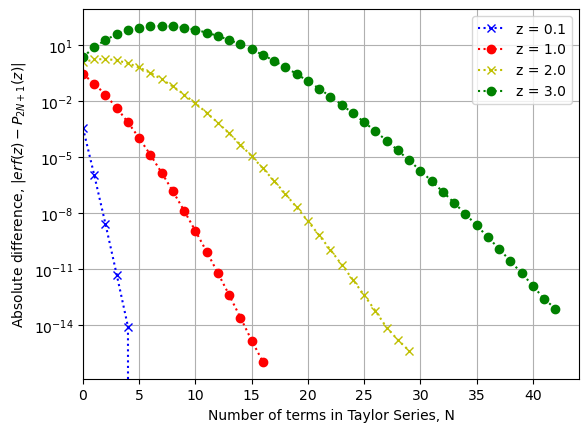

In [16]:
import math
import matplotlib.pyplot as plt

#Calculating P_{2N+1}(z)
def errfun(z,N):
    sum = 0

    #Adds sum up to N
    for n in range(0,N+1):
        sum += ((-1)**n * z**(2 * n + 1)) / (math.factorial(n) * (2 * n + 1))
        
    return (2 * sum / math.sqrt(math.pi))

#Check if our estimation function works
print(math.erf(1)), print(errfun(1,18))

#Function to calculate sequence of abs differnece until abs differnce is less than a given tolerance
def ErrSequence(z,eps):
    
    #Setting variables
    error = math.erf(z)
    difflist= [] 
    diff = eps + 1
    n = 0

    #Getting abs diff values while abs difference greater than a given tolerance
    while diff > eps:
        diff = abs(error - errfun(z,n))
        difflist.append(diff)
        n += 1
        
    return difflist

#Setting variables
eps1 = 1e-15
eps2 = 1e-13
diff01 = ErrSequence(0.1,eps1)
diff1 = ErrSequence(1.0,eps1)
diff2 = ErrSequence(2.0,eps1)
diff3 = ErrSequence(3.0,eps2)

#Plotting Graph
plt.semilogy(range(0,len(diff01)),diff01,'b:x',label='z = 0.1')
plt.semilogy(range(0,len(diff1)),diff1,'r:o',label='z = 1.0')
plt.semilogy(range(0,len(diff2)),diff2,'y:x',label='z = 2.0')
plt.semilogy(range(0,len(diff3)),diff3,'g:o',label='z = 3.0')

#Adding labels and grid
plt.xlabel('Number of terms in Taylor Series, N')
plt.ylabel(r'Absolute difference, $|erf(z) - P_{2N+1}(z)|$')
plt.grid(True)
plt.legend()

#limiting x-axis
plt.xlim(0)

#Save plot to a PDF file
plt.savefig('erf_convergence.pdf')

#Printing N, min, and max values for debugging purposes
print(f"z = 0.1 -> N = {len(diff01)-1}, min = {min(diff01)}, max = {max(diff01)}")
print(f"z = 1.0 -> N = {len(diff1)-1}, min = {min(diff1)}, max = {max(diff1)}")
print(f"z = 2.0 -> N = {len(diff2)-1}, min = {min(diff2)}, max = {max(diff2)}")
print(f"z = 3.0 -> N = {len(diff3)-1}, min = {min(diff3)}, max = {max(diff3)}")